In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df = pd.read_csv("C:\\Users\\hassa\\Downloads\\MLB-Internship\\Day4\\Practice\\CleanedStudentPerformance.csv")

print("Student Score Prediction System")
print("Dataset Loaded Successfully!")

print(df.head())

Student Score Prediction System
Dataset Loaded Successfully!
   gender Race_Ethnicity  Parental_Education         lunch Test_Preparation  \
0  female        group B   bachelor's degree      standard             none   
1  female        group C        some college      standard        completed   
2  female        group B     master's degree      standard             none   
3    male        group A  associate's degree  free/reduced             none   
4    male        group C        some college      standard             none   

   Math_Score  Reading_Score  Writing_Score  Average_Score        Performance  
0   66.029146       72.00000           74.0      70.676382            Average  
1   69.000000       69.18191           88.0      75.393970            Average  
2   66.029146       95.00000           93.0      84.676382               Good  
3   47.000000       69.18191           44.0      53.393970  Needs Improvement  
4   66.029146       78.00000           75.0      73.009715      

In [5]:
df["Average_Score"] = (
    df["Math_Score"] +
    df["Reading_Score"] +
    df["Writing_Score"]
) / 3

print(df[["Math_Score", "Reading_Score", "Writing_Score", "Average_Score"]].head())

   Math_Score  Reading_Score  Writing_Score  Average_Score
0   66.029146       72.00000           74.0      70.676382
1   69.000000       69.18191           88.0      75.393970
2   66.029146       95.00000           93.0      84.676382
3   47.000000       69.18191           44.0      53.393970
4   66.029146       78.00000           75.0      73.009715


In [6]:
df = pd.get_dummies(df, dtype=int)

print("Categorical Columns Encoded Successfully!")

print(df.head())

Categorical Columns Encoded Successfully!
   Math_Score  Reading_Score  Writing_Score  Average_Score  gender_female  \
0   66.029146       72.00000           74.0      70.676382              1   
1   69.000000       69.18191           88.0      75.393970              1   
2   66.029146       95.00000           93.0      84.676382              1   
3   47.000000       69.18191           44.0      53.393970              0   
4   66.029146       78.00000           75.0      73.009715              0   

   gender_male  Race_Ethnicity_group A  Race_Ethnicity_group B  \
0            0                       0                       1   
1            0                       0                       0   
2            0                       0                       1   
3            1                       1                       0   
4            1                       0                       0   

   Race_Ethnicity_group C  Race_Ethnicity_group D  ...  \
0                       0               

In [8]:
X = df.drop(["Average_Score", "Writing_Score"], axis=1)

y = df["Average_Score"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Math_Score  Reading_Score  gender_female  gender_male  \
0   66.029146       72.00000              1            0   
1   69.000000       69.18191              1            0   
2   66.029146       95.00000              1            0   
3   47.000000       69.18191              0            1   
4   66.029146       78.00000              0            1   

   Race_Ethnicity_group A  Race_Ethnicity_group B  Race_Ethnicity_group C  \
0                       0                       1                       0   
1                       0                       0                       1   
2                       0                       1                       0   
3                       1                       0                       0   
4                       0                       0                       1   

   Race_Ethnicity_group D  Race_Ethnicity_group E  \
0                       0                       0   
1                       0                       0   
2      

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (800, 23)
Testing Data: (200, 23)


In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


In [11]:
model = LinearRegression()

model.fit(X_train_scaled, y_train)

print("Model Trained Successfully!")

Model Trained Successfully!


In [12]:
y_pred = model.predict(X_test_scaled)

print("Predicted Average Scores:")
print(y_pred[:10])

Predicted Average Scores:
[88.80480023 61.83312054 75.60314007 74.02403851 82.35118694 76.49913616
 68.97960491 59.35338421 77.72325726 52.16930218]


In [13]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Metrics")

print("MAE:", mae)

print("MSE:", mse)

print("R2 Score:", r2)

Model Evaluation Metrics
MAE: 1.0896796071559953
MSE: 1.7924486524837453
R2 Score: 0.9916198649225505


In [14]:
comparison = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": y_pred
})

print(comparison.head(10))

   Actual Score  Predicted Score
0     87.000000        88.804800
1     64.000000        61.833121
2     75.000000        75.603140
3     74.666667        74.024039
4     81.666667        82.351187
5     78.000000        76.499136
6     67.333333        68.979605
7     59.000000        59.353384
8     77.333333        77.723257
9     48.666667        52.169302


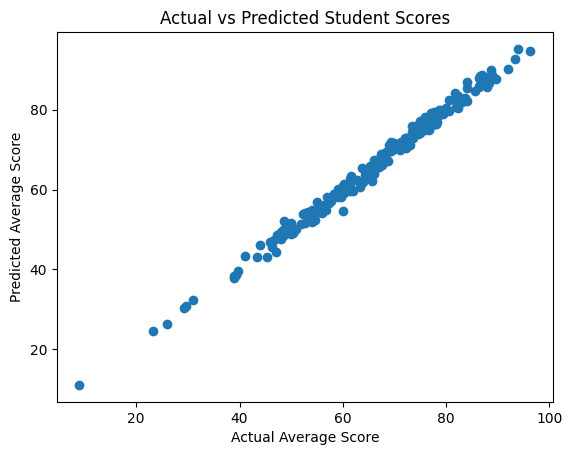

In [16]:
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Average Score")

plt.ylabel("Predicted Average Score")

plt.title("Actual vs Predicted Student Scores")

plt.savefig("actual_vs_predicted.png")

plt.show()